In [1]:
from pathlib import Path
import random
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "final"
    / "model_features_20d_provisional.csv"
)

TABLES_DIR = PROJECT_ROOT / "tables"
MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR = PROJECT_ROOT / "figures"

for folder in [TABLES_DIR, MODELS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("Project root:", PROJECT_ROOT)

TensorFlow version: 2.22.0-rc0
Project root: C:\Users\ibrah\RPDA8412 Research Project


In [2]:
df = pd.read_csv(
    DATA_PATH,
    parse_dates=["Date"]
)

df = df.sort_values("Date").reset_index(drop=True)

MARKET_FEATURES = [
    "Return_Lag1",
    "Absolute_Return",
    "RV_Historical_5D",
    "RV_Historical_10D",
    "RV_Historical_20D",
    "RV_Historical_60D",
    "RV_20D_Lag1"
]

TARGET = "RV_Future_20D"

HORIZON = 20
SEQUENCE_LENGTH = 20

assert df["Date"].is_monotonic_increasing
assert df["Date"].is_unique
assert df[MARKET_FEATURES + [TARGET]].notna().all().all()

print("Dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

Dataset shape: (3944, 17)
Date range: 2010-03-31 00:00:00 to 2025-12-02 00:00:00


In [3]:
development_start = pd.Timestamp("2018-01-01")
validation_start = pd.Timestamp("2020-01-01")
validation_end = pd.Timestamp("2022-12-31")

development_indices = df.index[
    (df["Date"] >= development_start)
    & (df["Date"] < validation_start)
].to_numpy()

validation_indices = df.index[
    (df["Date"] >= validation_start)
    & (df["Date"] <= validation_end)
].to_numpy()

first_dev_idx = development_indices[0]
first_val_idx = validation_indices[0]

# Strictly pre-development target availability.
initial_train_indices = np.arange(
    0,
    first_dev_idx - HORIZON
)

# Strictly pre-validation target availability.
final_train_indices = np.arange(
    0,
    first_val_idx - HORIZON
)

print("Initial training:", len(initial_train_indices))
print("Development:", len(development_indices))
print("Final training:", len(final_train_indices))
print("External validation:", len(validation_indices))

assert len(validation_indices) == 756
assert initial_train_indices[-1] + HORIZON < first_dev_idx
assert final_train_indices[-1] + HORIZON < first_val_idx

print("Chronological splits verified!")

Initial training: 1933
Development: 503
Final training: 2436
External validation: 756
Chronological splits verified!


In [4]:
def make_sequences(
    scaled_features,
    targets,
    forecast_indices,
    sequence_length=20
):
    X_sequences = []
    y_sequences = []

    for idx in forecast_indices:
        start = idx - sequence_length + 1

        if start < 0:
            continue

        X_sequences.append(
            scaled_features[start:idx + 1]
        )

        y_sequences.append(targets[idx])

    return (
        np.asarray(X_sequences, dtype=np.float32),
        np.asarray(y_sequences, dtype=np.float32)
    )

In [5]:
scaler_dev = StandardScaler()

scaler_dev.fit(
    df.loc[initial_train_indices, MARKET_FEATURES]
)

X_all_dev = scaler_dev.transform(
    df[MARKET_FEATURES]
)

y_all = df[TARGET].to_numpy()

X_train, y_train = make_sequences(
    X_all_dev,
    y_all,
    initial_train_indices,
    SEQUENCE_LENGTH
)

X_dev, y_dev = make_sequences(
    X_all_dev,
    y_all,
    development_indices,
    SEQUENCE_LENGTH
)

print("Training sequences:", X_train.shape)
print("Development sequences:", X_dev.shape)

assert X_train.shape[1:] == (20, 7)
assert X_dev.shape[1:] == (20, 7)

Training sequences: (1914, 20, 7)
Development sequences: (503, 20, 7)


In [6]:
def build_lstm(seed=42):

    tf.keras.backend.clear_session()

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    model = Sequential([
        Input(shape=(20, 7)),
        LSTM(32),
        Dropout(0.2),
        Dense(16, activation="relu"),
        Dense(1, activation="softplus")
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    return model

In [7]:
development_model = build_lstm(seed=42)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = development_model.fit(
    X_train,
    y_train,
    validation_data=(X_dev, y_dev),
    epochs=50,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)

best_epoch = int(
    np.argmin(history.history["val_loss"]) + 1
)

print("\nBest development epoch:", best_epoch)
print(
    "Best development loss:",
    min(history.history["val_loss"])
)


Epoch 1/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.2307 - mae: 0.4300 - val_loss: 0.0981 - val_mae: 0.2392
Epoch 2/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0471 - mae: 0.1413 - val_loss: 0.0018 - val_mae: 0.0314
Epoch 3/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0013 - mae: 0.0240 - val_loss: 4.5048e-04 - val_mae: 0.0155
Epoch 4/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.4723e-04 - mae: 0.0186 - val_loss: 4.6233e-04 - val_mae: 0.0159
Epoch 5/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.3365e-04 - mae: 0.0180 - val_loss: 4.7769e-04 - val_mae: 0.0162
Epoch 6/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.2277e-04 - mae: 0.0179 - val_loss: 4.7805e-04 - val_mae: 0.0161
Epoch 7/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.2006e-04 - mae: 0.0179 - val_loss: 4.8047e-04 - val_mae: 0.0161
Epoch 8/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.9880e-04 - mae: 0.0180 - val_loss: 4.8321e-04 - val_mae: 0.0161
Epoch 9/50
60/60 ━━━━━━━━━

In [8]:
scaler_final = StandardScaler()

scaler_final.fit(
    df.loc[final_train_indices, MARKET_FEATURES]
)

X_all_final = scaler_final.transform(
    df[MARKET_FEATURES]
)

X_final_train, y_final_train = make_sequences(
    X_all_final,
    y_all,
    final_train_indices,
    SEQUENCE_LENGTH
)

X_validation, y_validation = make_sequences(
    X_all_final,
    y_all,
    validation_indices,
    SEQUENCE_LENGTH
)

print("Final training sequences:", X_final_train.shape)
print("Validation sequences:", X_validation.shape)

final_lstm = build_lstm(seed=42)

final_lstm.fit(
    X_final_train,
    y_final_train,
    epochs=best_epoch,
    batch_size=32,
    shuffle=False,
    verbose=1
)

Final training sequences: (2417, 20, 7)
Validation sequences: (756, 20, 7)
Epoch 1/3
76/76 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1996 - mae: 0.3852
Epoch 2/3
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0170 - mae: 0.0739
Epoch 3/3
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 7.2588e-04 - mae: 0.0195


In [9]:
lstm_predictions = final_lstm.predict(
    X_validation,
    verbose=0
).reshape(-1)

lstm_predictions = np.maximum(
    lstm_predictions,
    0
)

lstm_results = pd.DataFrame({
    "Date": df.loc[validation_indices, "Date"].to_numpy(),
    "Actual": y_validation,
    "Predicted": lstm_predictions
})

assert len(lstm_results) == 756
assert np.isfinite(lstm_results["Predicted"]).all()

display(lstm_results.head())

,Date,Actual,Predicted
0,2020-01-02,0.032513,0.020162
1,2020-01-03,0.032545,0.020141
2,2020-01-06,0.035606,0.020081
3,2020-01-07,0.037217,0.019717
4,2020-01-08,0.037043,0.019820


In [10]:
def evaluate_model(y_true, y_pred, epsilon=1e-4):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    mae = mean_absolute_error(y_true, y_pred)

    safe_mape = np.mean(
        np.abs(y_true - y_pred)
        / np.maximum(np.abs(y_true), epsilon)
    ) * 100

    return {
        "RMSE": rmse,
        "MAE": mae,
        "Safe_MAPE": safe_mape
    }


lstm_metrics = evaluate_model(
    lstm_results["Actual"],
    lstm_results["Predicted"]
)

print("=" * 55)
print("REFINED LSTM VALIDATION RESULTS")
print("=" * 55)

for metric, value in lstm_metrics.items():
    print(f"{metric}: {value:.6f}")

REFINED LSTM VALIDATION RESULTS
RMSE: 0.044545
MAE: 0.026177
Safe_MAPE: 37.665306


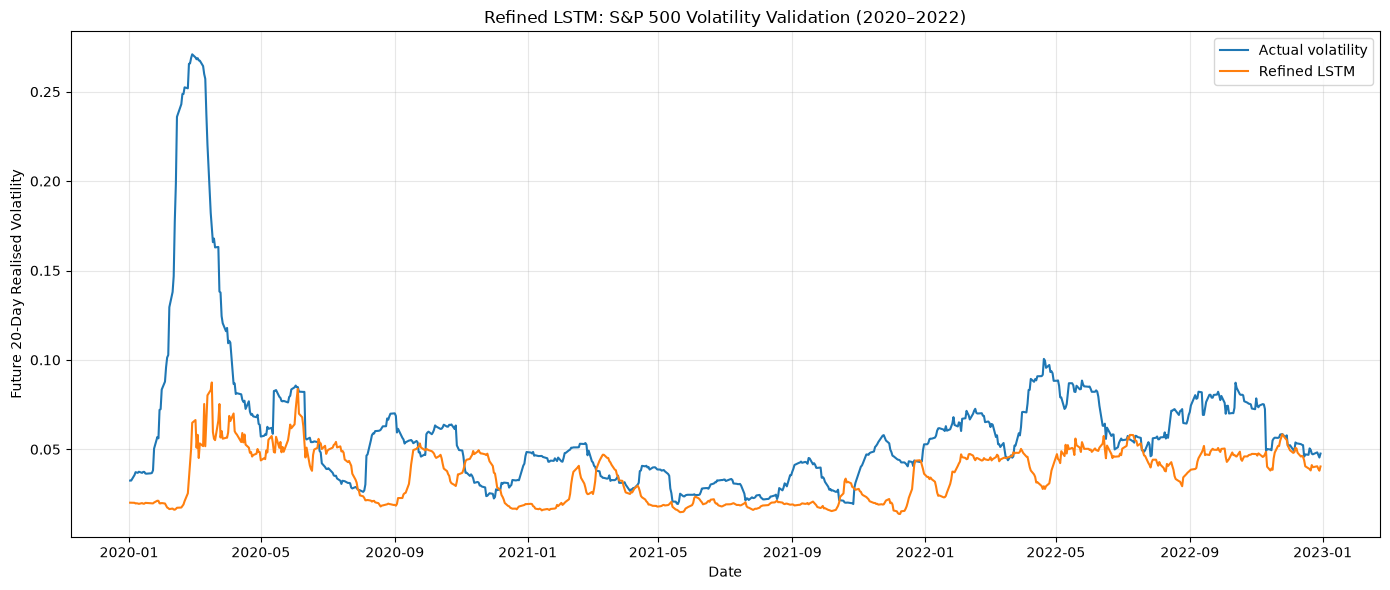

Notebook 15 results saved!


In [11]:
lstm_results.to_csv(
    TABLES_DIR / "lstm_refined_validation_predictions.csv",
    index=False
)

final_lstm.save(
    MODELS_DIR / "lstm_refined_validation.keras"
)

plt.figure(figsize=(14, 6))

plt.plot(
    lstm_results["Date"],
    lstm_results["Actual"],
    label="Actual volatility"
)

plt.plot(
    lstm_results["Date"],
    lstm_results["Predicted"],
    label="Refined LSTM"
)

plt.title("Refined LSTM: S&P 500 Volatility Validation (2020–2022)")
plt.xlabel("Date")
plt.ylabel("Future 20-Day Realised Volatility")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "lstm_refined_validation.png",
    dpi=300
)

plt.show()

print("Notebook 15 results saved!")

In [12]:
SEEDS = [11, 21, 42, 84, 123]

seed_results = []
seed_predictions = {}

for seed in SEEDS:

    print(f"\nTraining LSTM with seed {seed}")

    model = build_lstm(seed=seed)

    model.fit(
        X_final_train,
        y_final_train,
        epochs=best_epoch,
        batch_size=32,
        shuffle=False,
        verbose=0
    )

    predictions = model.predict(
        X_validation,
        verbose=0
    ).reshape(-1)

    predictions = np.maximum(predictions, 0)

    metrics = evaluate_model(
        y_validation,
        predictions
    )

    seed_results.append({
        "Seed": seed,
        **metrics
    })

    seed_predictions[seed] = predictions

    print(
        f"RMSE: {metrics['RMSE']:.6f} | "
        f"MAE: {metrics['MAE']:.6f}"
    )

seed_comparison = pd.DataFrame(seed_results)

display(seed_comparison.round(6))


Training LSTM with seed 11
RMSE: 0.046915 | MAE: 0.029234

Training LSTM with seed 21
RMSE: 0.050369 | MAE: 0.033982

Training LSTM with seed 42
RMSE: 0.044545 | MAE: 0.026177

Training LSTM with seed 84
RMSE: 0.043093 | MAE: 0.023986

Training LSTM with seed 123
RMSE: 0.040740 | MAE: 0.024521


,Seed,RMSE,MAE,Safe_MAPE
0,11,0.046915,0.029234,43.382397
1,21,0.050369,0.033982,49.280678
2,42,0.044545,0.026177,37.665310
3,84,0.043093,0.023986,36.721390
4,123,0.040740,0.024521,47.969715


In [13]:
print("=" * 60)
print("LSTM REPRODUCIBILITY SUMMARY")
print("=" * 60)

summary = seed_comparison[
    ["RMSE", "MAE", "Safe_MAPE"]
].agg(["mean", "std", "min", "max"])

display(summary.round(6))

seed_comparison.to_csv(
    TABLES_DIR / "lstm_seed_comparison.csv",
    index=False
)

summary.to_csv(
    TABLES_DIR / "lstm_reproducibility_summary.csv"
)

print("Reproducibility results saved!")

LSTM REPRODUCIBILITY SUMMARY


,RMSE,MAE,Safe_MAPE
mean,0.045132,0.027580,43.003895
std,0.003688,0.004122,5.748283
min,0.040740,0.023986,36.721390
max,0.050369,0.033982,49.280678


Reproducibility results saved!
